Loading telco customer churn dataset...

Dataset type: <class 'pandas.DataFrame'>
Number of samples: 7043
Number of features: 21

First few rows:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              

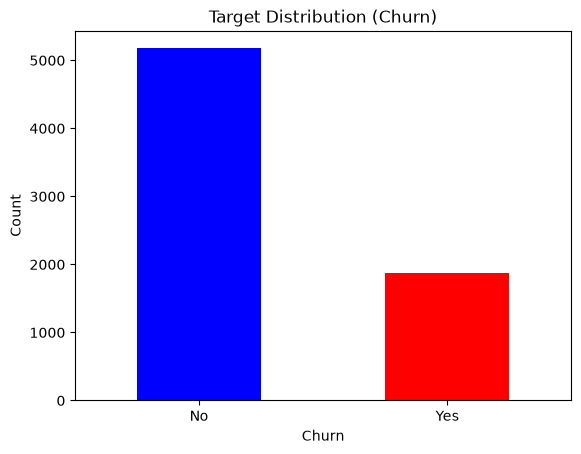

In [7]:
"""
Telco Customer Churn Prediction with KNN
Author: Chris Fulton
Description: Predict whether Telco customers churn rate using a KNN
"""

# Step 1 - Load and Explore the Data 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report

print("Loading telco customer churn dataset...")
df = pd.read_csv('Telco-Customer-Churn.csv')

# data exploration
print(f"\nDataset type: {type(df)}")
print(f"Number of samples: {len(df)}")  # samples = Rows
print(f"Number of features: {len(df.columns)}")  # features = Columns

# Display first few rows
print("\nFirst few rows:")
print(df.head())

# Display dataset info
print("\nDataset info:")
print(df.info())

# Check target distribution ('Churn' column)
print("\nTarget distribution:")
print(df['churn'].value_counts() if 'churn' in df.columns else df['Churn'].value_counts())

(df['churn'] if 'churn' in df.columns else df['Churn']).value_counts().plot(kind='bar', color=['blue', 'red'])
plt.title('Target Distribution (Churn)')
plt.xlabel('Churn')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()


# Experimenting with new commands
import seaborn as sns
import matplotlib.pyplot as plt

# Check correlation with the target (ensure churn is encoded as 0/1 first)
numeric_df = df.select_dtypes(include=[np.number])
correlation = numeric_df.corr(numeric_only=True)['Churn'].sort_values(ascending=False)
print(correlation)

print(f"\nColumns missing data: ")
print(df.isnull().sum())

In [ ]:
# Step 2 - Data Preprocessing

print("="*50)
print("DATA PREPROCESSING")
print("="*50)

if 'customerID' in df.columns:
    df = df.drop('customerID', axis=1)
# here we are just removing unnecesary columbs that dont have any effect on the outcome ofpredictions


df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
# the code is a critical step turning the values into float ro integers. Also 'coerce' fills in blank values with NaN instead of throwing an error. 

median_total_charges = df['TotalCharges'].median()
df['TotalCharges'] = df['TotalCharges'].fillna(median_total_charges)
print(f"Filled missing TotalCharges with median: {median_total_charges}")
print(f"Dataset shape after handling missing values: {df.shape}")
# this code just establises the median in the total charges column and gives it a varible name. Also know it is wise to use median in financial figures to offset statistical outliers
# the df.shape function return the rows vs columns of the dataset.

df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
# this code converts the string into numbers for the models use. The map function is a simple way to convert to numbers 
print("\nTarget distribution (Churn):")
print(df['Churn'].value_counts())

features = ['tenure', 'MonthlyCharges', 'TotalCharges']
X = df[features]
y = df['Churn']

print(f"\nFeatures shape (X): {X.shape}")
print(f"Target shape (y): {y.shape}")

DATA PREPROCESSING
Filled missing TotalCharges with median: 1397.475
Dataset shape after handling missing values: (7043, 20)

Target distribution (Churn):
Churn
0    5174
1    1869
Name: count, dtype: int64

Features shape (X): (7043, 3)
Target shape (y): (7043,)


In [ ]:
# Step 3: Data Split

print("="*50)
print("DATA SPLIT")
print("="*50)


# splitting the groups using 80/20 as the standard. stratify just means that the same proportions will be used from the y axis.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, #hitchhikers lyfe
    stratify=y
)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")
print(f"Training features: {X_train.shape[1]}")
print(f"Test features: {X_test.shape[1]}")
#just confirmining the figures after split are as expected

print("\nTraining set target distribution:")
print(y_train.value_counts())
print(f"  Retained (0): {(y_train == 0).sum()} ({(y_train == 0).mean()*100:.1f}%)")
print(f"  Churned (1): {(y_train == 1).sum()} ({(y_train == 1).mean()*100:.1f}%)")

print("\nTest set target distribution:")
print(y_test.value_counts())
print(f"  Retained (0): {(y_test == 0).sum()} ({(y_test == 0).mean()*100:.1f}%)")
print(f"  Churned (1): {(y_test == 1).sum()} ({(y_test == 1).mean()*100:.1f}%)")

DATA SPLIT
Training set size: 5634 samples
Test set size: 1409 samples
Training features: 3
Test features: 3

Training set target distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64
  Retained (0): 4139 (73.5%)
  Churned (1): 1495 (26.5%)

Test set target distribution:
Churn
0    1035
1     374
Name: count, dtype: int64
  Retained (0): 1035 (73.5%)
  Churned (1): 374 (26.5%)


In [19]:
from sklearn.preprocessing import StandardScaler

print("="*50)
print("TRAINING THE KNN MODEL")
print("="*50)

# Scale features so distance-based calculations treat all columns equally
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)

# Train using the scaled training data
knn.fit(X_train_scaled, y_train)

print("KNN classifier trained successfully!")
print(f"Number of neighbors (k): {knn.n_neighbors}")
# checking the n_neighbours value is accurate.

# Generate predictions using the scaled features
y_train_pred = knn.predict(X_train_scaled)
y_test_pred = knn.predict(X_test_scaled)

print(f"\nTraining predictions: {len(y_train_pred)}")
print(f"Test predictions: {len(y_test_pred)}")

# Sanity check used from Part 1
print("\nModel Predictions:", y_test_pred[:15])
print("Actual Answers:   ", y_test.values[:15])

TRAINING THE KNN MODEL
KNN classifier trained successfully!
Number of neighbors (k): 5

Training predictions: 5634
Test predictions: 1409

Model Predictions: [0 1 0 0 0 1 1 0 0 0 0 0 0 1 0]
Actual Answers:    [0 0 0 0 0 0 0 0 0 1 0 0 0 1 0]


In [ ]:
# Step 5: Model Evaluation and Performance Metrics

print("="*50)
print("MODEL PERFORMANCE EVALUATION (k=5)")
print("="*50)

# Calculate evaluation metrics using test predictions
accuracy = accuracy_score(y_test, y_test_pred)
# shows score for correctly guessing the outcome of the model for both churners and retained combined
precision = precision_score(y_test, y_test_pred)
# precision
recall = recall_score(y_test, y_test_pred)
conf_matrix = confusion_matrix(y_test, y_test_pred)
# Breaks down the predictions into True Neg, False Pos, False Neg, and True Pos to give a complete picture of where the KNN model makes mistakes.
class_report = classification_report(y_test, y_test_pred)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")

print("\nConfusion Matrix:")
print(conf_matrix)

print("\nClassification Report:")
print(class_report)

MODEL PERFORMANCE EVALUATION (k=5)
Accuracy:  0.7630
Precision: 0.5714
Recall:    0.4278

Confusion Matrix:
[[915 120]
 [214 160]]

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.88      0.85      1035
           1       0.57      0.43      0.49       374

    accuracy                           0.76      1409
   macro avg       0.69      0.66      0.67      1409
weighted avg       0.75      0.76      0.75      1409



## OBSERVATIONS
The model is showing an accuracy of 76%, which seems like a reasonable level for prediction. However, its low recall of 43% for the churn class means it is missing alot clients who are leaving. This may be bacuse as shown in step 3:  

Retained (0): 1035 (73.5%)
Churned (1): 374 (26.5%)

There are 3 times as many retained rows compared to churned. I may need to increase my k value for this data set. The confusion matrix drives home that this model is not bad a telling me who will stay, but quite poor at telling me who will churn.

EXPERIMENTING WITH DIFFERENT K VALUES
k =  1 | Test Accuracy: 0.7083
k =  3 | Test Accuracy: 0.7580
k =  5 | Test Accuracy: 0.7630
k =  7 | Test Accuracy: 0.7835
k =  9 | Test Accuracy: 0.7864
k = 11 | Test Accuracy: 0.7857
k = 15 | Test Accuracy: 0.7885

Best k value based on Argmax funtion: 15 with an accuracy of 0.7885
Best k value based on my own opinion: 7 with an accuracy of 0.7835

Saved visualization to 'churn_k_comparison.png'


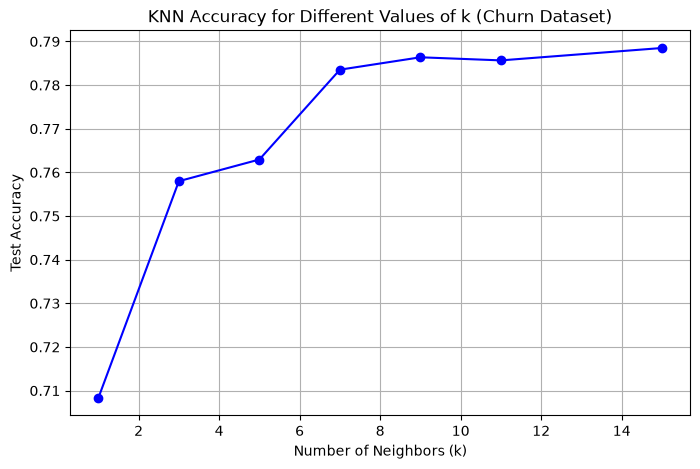

In [21]:
# Step 6: Experiment and Improve (Hyperparameter Tuning for k)

print("="*50)
print("EXPERIMENTING WITH DIFFERENT K VALUES")
print("="*50)

k_values = [1, 3, 5, 7, 9, 11, 15]
accuracies = []

for k in k_values:
    # Train model with current k
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train, y_train)
    
    # Predict and calculate accuracy
    preds = knn_temp.predict(X_test)
    acc = accuracy_score(y_test, preds)
    accuracies.append(acc)
    print(f"k = {k:2d} | Test Accuracy: {acc:.4f}")

# Find the best k value and its accuracy
best_k = k_values[np.argmax(accuracies)]
best_accuracy = max(accuracies)

print("\n" + "="*50)
print(f"Best k value based on Argmax funtion: {best_k} with an accuracy of {best_accuracy:.4f}")
print(f"Best k value based on my own opinion: 7 with an accuracy of 0.7835")
print("="*50)

# Visualize accuracy across different k values
plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker='o', linestyle='-', color='b')
plt.title('KNN Accuracy for Different Values of k (Churn Dataset)')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Test Accuracy')
plt.grid(True)
plt.savefig('churn_k_comparison.png', dpi=150, bbox_inches='tight')
print("\nSaved visualization to 'churn_k_comparison.png'")
plt.show()

Observations: A very small choce of k=1 look to be resulting in 'overfitting' to the training data, capturing trends by proximity rather than general trends, which should lead to innaccurate findings. It appears there is a sharp plateau after k=7 which is why i chose it over k=15 as there is a negligable increase in accuracy, whilst avoiding unneccessary added complexity to the model.

Step 7: Analysis and Recommendations
What is the model's accuracy?
What features seem most important? (You can explore this by looking at feature distributions)
What would you recommend to the company based on your model?
What are the limitations of your model?